In [26]:
# Import Essential Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from datetime import timedelta
from pandas.plotting import register_matplotlib_converters
from statsmodels.tsa.statespace.sarimax import SARIMAX
register_matplotlib_converters()
from time import time

# Prepare Bicycle Dataset
Use dtheday as the date and cnt as total daily rentals. One row is one day across the recorded system; cnt is not the number of unique people or bikes needed at a station.
- Parse and sort dates.
- Check for duplicate dates.
- Check for missing calendar days.
- Check for missing count values.
- Check for negative or non-integer counts.

Record each findings. The unmodified daily file should contain 731 dates from January 1 2011 to December 31 2012. **If checks fails fail, do not invent observations or silently delete dates.** Use only the dated ctn series as the SARIMA input. Other fields, including casual, registered, and measured weather, are not model inputs. You do not need to create lag_1 or lag_7 feature columns; SARIMA handles its own time dependence.

> Inspecting the dataset.

In [27]:
# The program below loads data from day.csv. It parses the date to be in day/month/Year format. Sort the data dteday.
# Marking the the dteday as the index column unlocks pandas' built in time-series-engine,
# which makes queries and plotting easier.
bike_shares = pd.read_csv("../data/raw/day.csv", index_col="dteday")
bike_shares.index = pd.to_datetime(bike_shares.index, format="%Y-%m-%d")
bike_shares = bike_shares.sort_index()
print(bike_shares.head())
print(bike_shares.tail())
print(bike_shares.dtypes)
print(bike_shares.index.dtype)

            instant  season  yr  mnth  holiday  weekday  workingday  \
dteday                                                                
2011-01-01        1       1   0     1        0        6           0   
2011-01-02        2       1   0     1        0        0           0   
2011-01-03        3       1   0     1        0        1           1   
2011-01-04        4       1   0     1        0        2           1   
2011-01-05        5       1   0     1        0        3           1   

            weathersit      temp     atemp       hum  windspeed  casual  \
dteday                                                                    
2011-01-01           2  0.344167  0.363625  0.805833   0.160446     331   
2011-01-02           2  0.363478  0.353739  0.696087   0.248539     131   
2011-01-03           1  0.196364  0.189405  0.437273   0.248309     120   
2011-01-04           1  0.200000  0.212122  0.590435   0.160296     108   
2011-01-05           1  0.226957  0.229270  0.436957

In [28]:
# Checking for duplicate dates.
assert bike_shares.index.duplicated().sum() == 0, "Data set contains duplicated dates."
if bike_shares.index.duplicated().sum() > 0:
    print(bike_shares[bike_shares.index.duplicated()])
else:
    print("No duplicate dates found.")

# Check for missing calendar days.
#January 1 2011 to December 31 2012
start_date = datetime(2011, 1, 1)
end_date = datetime(2012, 12, 31)
missing_dates = pd.date_range(start=start_date, end=end_date).difference(pd.to_datetime(bike_shares.index))
assert len(missing_dates) == 0, "Data set contains missing dates."
if len(missing_dates) > 0:
    print(missing_dates)
else:
    print("No missing dates found")

# Check for missing count values.
assert bike_shares.cnt.isna().sum() == 0, "Data set contains missing value."
if bike_shares.cnt.isna().sum() > 0:
    print(bike_shares[bike_shares.cnt.isna()])
else:
    print("No missing count values found")

# Check for negative or non-integer counts
# First, converts all ctn records to numeric (e.g. int64 or float64).
# It ensures that strings are converted to proper numerical data types
# and non numerical data is converted into NaN.
invalid_mask =  (bike_shares.cnt < 0) | ((bike_shares.cnt % 1) != 0)
assert not invalid_mask.any(), "Data set contains negative or non-integer values"
if invalid_mask.any():
    print(bike_shares[invalid_mask])
else:
    print("No negative or non-integer values found.")

No duplicate dates found.
No missing dates found
No missing count values found
No negative or non-integer values found.


In [29]:
print(bike_shares.index.value_counts().sum())

731


Based on the outputs, the bike_shares data set is clean. It does not contain:
- any duplicated dates, 
- missing dates, 
- missing daily rental records, and 
- invalid daily rental records.

It is also confirmed that the dataset contains exactly 731 records.

# Separate Past Evidence From Future Prediction

In [30]:
# Training dataset
training_start_date = datetime(2011,1,1)
training_end_date = datetime(2012,12,17)
training_set = bike_shares.loc[training_start_date.strftime("%Y-%m-%d"):training_end_date.strftime("%Y-%m-%d")]["cnt"]
print(training_set.head())
print(training_set.tail())



dteday
2011-01-01     985
2011-01-02     801
2011-01-03    1349
2011-01-04    1562
2011-01-05    1600
Name: cnt, dtype: int64
dteday
2012-12-13    5532
2012-12-14    5611
2012-12-15    5047
2012-12-16    3786
2012-12-17    4585
Name: cnt, dtype: int64


In [31]:
# Testing Dataset
test_start_date = datetime(2012,12,18)
test_end_date = datetime(2012,12,31)
test_set = bike_shares.loc[test_start_date.strftime("%Y-%m-%d"):test_end_date.strftime("%Y-%m-%d")]["cnt"]
print(test_set.head())
print(test_set.tail())

dteday
2012-12-18    5557
2012-12-19    5267
2012-12-20    4128
2012-12-21    3623
2012-12-22    1749
Name: cnt, dtype: int64
dteday
2012-12-27    2114
2012-12-28    3095
2012-12-29    1341
2012-12-30    1796
2012-12-31    2729
Name: cnt, dtype: int64


> I expect daily rentals to show a weekly pattern because the customer needs changes the demand throughout the week. My initial assumption: during weekdays, demands for bike rentals increased because of daily commuters (e.g. workers, students), whereas demands declines because daily commuters decreases and the focus shifts from commuting to leisure riding. As a result, there is a distinct difference between Monday-Friday and Saturday-Sunday rental volumes.

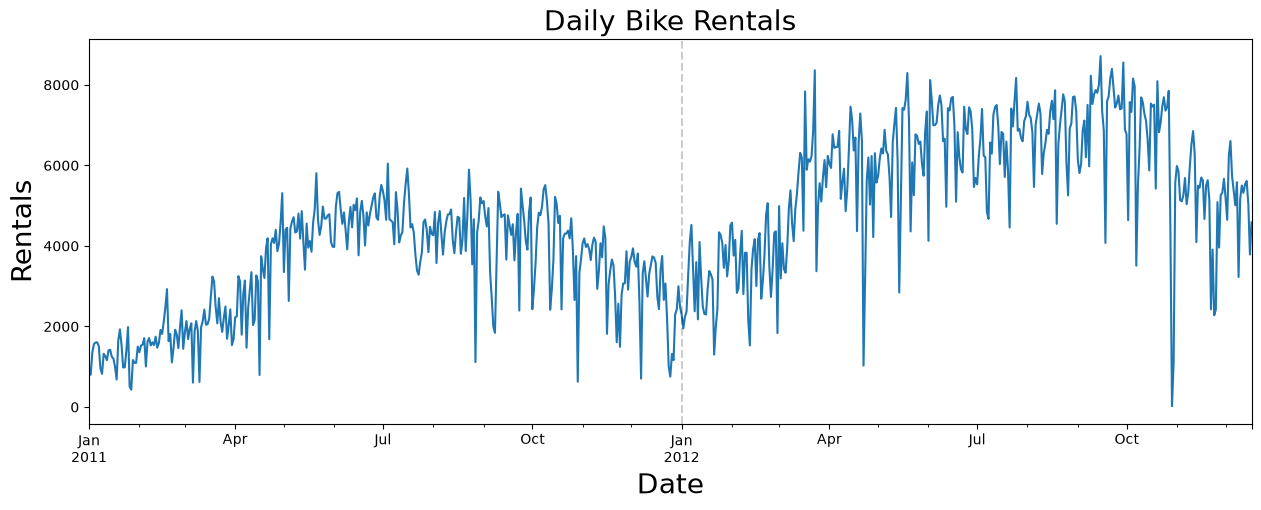

In [32]:

plt.figure(figsize=(15,5))
plt.title("Daily Bike Rentals", fontdict={"size": 20})
training_set.plot()
plt.xlabel("Date", fontdict={"size": 20})
plt.ylabel("Rentals", fontdict={"size": 20})

for year in range(start_date.year-1, end_date.year+1):
    plt.axvline(pd.to_datetime(str(year)+'-01-01'), color='k', linestyle='--', alpha=0.2) 

In [33]:
training_set.index.dtype
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekly_summary = (
    training_set.groupby(training_set.index.day_name())
    .agg(mean_rentals="mean", sample_size="count")
    .reindex(days_order)
)

print("Unsorted Weekly Summary")
print(weekly_summary)

print("\nSorted Weekly Summary")
print(weekly_summary.sort_values(by='mean_rentals'))

Unsorted Weekly Summary
           mean_rentals  sample_size
dteday                              
Monday      4386.932039          103
Tuesday     4534.696078          102
Wednesday   4581.764706          102
Thursday    4697.578431          102
Friday      4716.392157          102
Saturday    4608.902913          103
Sunday      4276.155340          103

Sorted Weekly Summary
           mean_rentals  sample_size
dteday                              
Sunday      4276.155340          103
Monday      4386.932039          103
Tuesday     4534.696078          102
Wednesday   4581.764706          102
Saturday    4608.902913          103
Thursday    4697.578431          102
Friday      4716.392157          102


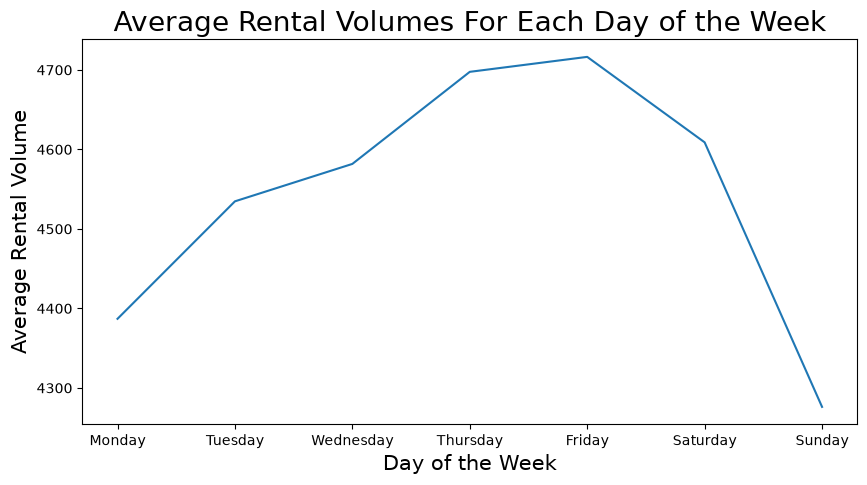

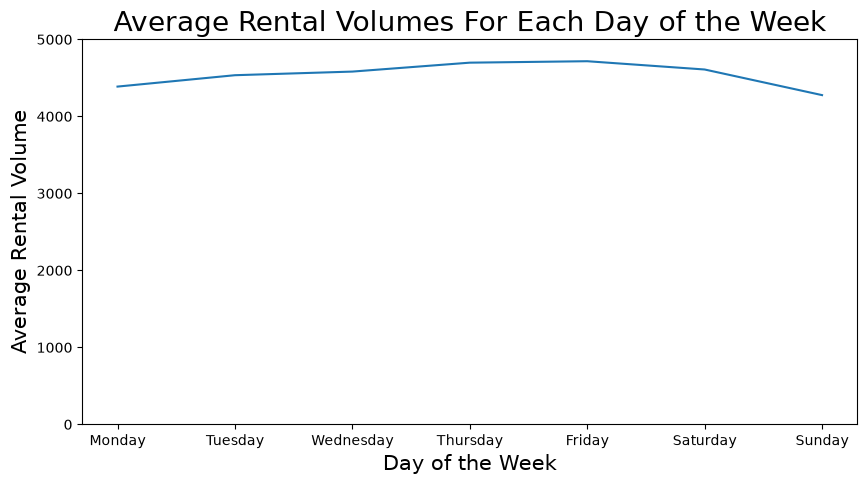

In [34]:
# Plotting Weekly Summary for easier analysis
plt.figure(figsize=(10,5))
plt.title("Average Rental Volumes For Each Day of the Week", fontdict={'size': 20})
weekly_summary['mean_rentals'].plot()
plt.xlabel("Day of the Week", fontdict={"size": 15})
plt.ylabel("Average Rental Volume", fontdict={"size": 15})
plt.show()
plt.figure(figsize=(10,5))
plt.title("Average Rental Volumes For Each Day of the Week", fontdict={'size': 20})
weekly_summary['mean_rentals'].plot()
plt.xlabel("Day of the Week", fontdict={"size": 15})
plt.ylabel("Average Rental Volume", fontdict={"size": 15})
plt.ylim(0, 5000)
plt.show()

In [36]:
max_mean = weekly_summary.loc[weekly_summary['mean_rentals'].idxmax()]
min_mean = weekly_summary.loc[weekly_summary['mean_rentals'].idxmin()]

# Prints the day of the week with the Highest Mean
print("Highest Training Mean")
print(max_mean)
# Prints the day of the week with the Lowest Mean
print("\nLowest Training Mean")
print(min_mean)
# The difference between max and min
print("\nDifference")
diff = max_mean.mean_rentals - min_mean.mean_rentals 
print(diff)
# Show the difference in a form of percentage
print( diff / max_mean.mean_rentals * 100)

print("\nHow many is retained?")
print(max_mean.mean_rentals - diff)
print((max_mean.mean_rentals - diff)/max_mean.mean_rentals * 100)


Highest Training Mean
mean_rentals    4716.392157
sample_size      102.000000
Name: Friday, dtype: float64

Lowest Training Mean
mean_rentals    4276.15534
sample_size      103.00000
Name: Sunday, dtype: float64

Difference
440.2368170569198
9.334186013695627

How many is retained?
4276.155339805825
90.66581398630437


**Which day of the week has the highest mean?**
- Friday, with an average of 4716.39 rental volumes

**which day of the week has the lowest mean?**
- Sunday, with an average of 4276.15 rental volumes

**Give both means and their difference.**
- `Difference=440.24`

**Does these support your expectation of weekly pattern? Explain that weekdays means alone do not prove a stable seven-day cycle or explain its cause.**
- Base on the outputs, the data does supports my expectations of weekly pattern. The weekly average of rental volume steadily increases during the weekdays and peaks at Friday (~4716), and it starts decreasing during the weekends and through at Sunday (~4276). However, the output neither prove that this cycle is consistent every week or explain the causes behind it. The 9% difference indicates that there is a very small fluctuation in average bike rentals, and a single outlier can significantly distort it. Moreover, the average does not take into account the impact of the weather, the type of customers, the holiday, the season, or the use-case. Therefore, the mean alone cannot fully prove that the pattern is caused by the changes in customer needs (e.g. commute to leisure).

# Train and Predict Using SARIMAX

In [37]:
order=(1,1,1)
seasonal_order=(1,0,1,7)
model = SARIMAX(training_set, order=order, seasonal_order=seasonal_order)

/home/kaiser/school/ds/UCI-Bike-Rental-Forecasting-With-SARIMA/.venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/kaiser/school/ds/UCI-Bike-Rental-Forecasting-With-SARIMA/.venv/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


In [ ]:
# Fit/train the model
# Disp=false, hides iterative solver logs
# maxiter, limit to 500 iterations.
fitted = model.fit(disp=False, maxiter=500)
# checks whether the numerical optimizer successfully settled on a stable solution or hit the 500-iteration without converging.
print("Converged: ", fitted.mle_retvals.get("converged") )

Converged:  True


In [47]:
# predict the next 14 days
fc = fitted.get_forecast(steps=14)
# calculate confidence interval
ci = fc.conf_int(alpha=0.05)
print(ci)

              lower cnt    upper cnt
2012-12-18  2981.459433  6522.353837
2012-12-19  3158.408629  7004.455180
2012-12-20  3035.990032  6967.610260
2012-12-21  3057.354530  7032.314314
2012-12-22  3008.249367  7015.528449
2012-12-23  2546.752700  6582.901135
2012-12-24  2766.052328  6829.836811
2012-12-25  2740.675458  6854.659167
2012-12-26  2980.409323  7129.877793
2012-12-27  2872.098196  7052.565875
2012-12-28  2891.938836  7101.839591
2012-12-29  2844.498261  7083.187665
2012-12-30  2408.455493  6675.593135
2012-12-31  2613.724968  6909.073703


            actual_cnt  predicted_cnt  baseline_cnt     lower_95     upper_95
2012-12-18        5557    4751.906635          5501  2981.459433  6522.353837
2012-12-19        5267    5081.431904          5319  3158.408629  7004.455180
2012-12-20        4128    5001.800146          5532  3035.990032  6967.610260
2012-12-21        3623    5044.834422          5611  3057.354530  7032.314314
2012-12-22        1749    5011.888908          5047  3008.249367  7015.528449
2012-12-23        1787    4564.826918          3786  2546.752700  6582.901135
2012-12-24         920    4797.944569          4585  2766.052328  6829.836811
2012-12-25        1013    4797.667313          5501  2740.675458  6854.659167
2012-12-26         441    5055.143558          5319  2980.409323  7129.877793
2012-12-27        2114    4962.332035          5532  2872.098196  7052.565875
2012-12-28        3095    4996.889214          5611  2891.938836  7101.839591
2012-12-29        1341    4963.842963          5047  2844.498261

<Axes: >

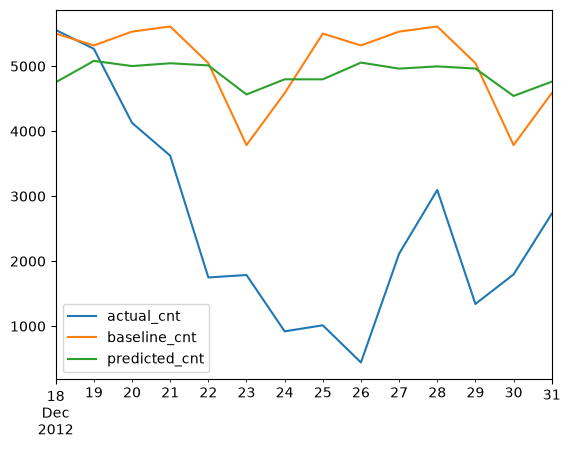

In [65]:
baseline = np.tile(training_set.iloc[-7:].to_numpy(), 2)
result = pd.DataFrame({
    "actual_cnt": test_set,
    "predicted_cnt": fc.predicted_mean,
    "baseline_cnt": baseline,
    "lower_95": ci.iloc[:, 0],
    "upper_95": ci.iloc[:, 1]
})

print(result)
result[["actual_cnt","baseline_cnt", "predicted_cnt"]].plot()

In [71]:
assert result.index.equals(test_set.index)
result["absolute_error"] = abs(result.actual_cnt-result.predicted_cnt)
result.rename_axis("date").to_csv("test_predictions.csv")